# HuRI PSI-MITAB notebook

## What the filters change

The supplied PSI file has **171,545 interaction records**. The app's default parent-accession view keeps **51,574 distinct undirected pairs** across **8,163 incident accessions**. Keeping isoforms distinct gives **51,575 pairs**. Requiring both source IDs to be unsuffixed gives **13,540 pairs**.

These figures describe the saved run. The cells below recompute the counts from the local source and check them against the app's prepared networks when their provenance matches.

## Setup

Open this notebook from the repository root or its notebooks directory. Use a Jupyter kernel with the project dependencies, ipykernel, and matplotlib. The notebook reads **data/raw_networks/HuRI.psi**, computes all three views in memory, and records the source SHA-256.

In [1]:
from hashlib import file_digest
from html import escape
from io import BytesIO
import json
from pathlib import Path
import sys

from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import polars as pl

cwd = Path.cwd()
root = next((path for path in (cwd, *cwd.parents) if (path / "networks.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Open the notebook from the interactome repository.")
sys.path.insert(0, str(root))

from networks import (
    HURI_ISOFORM_POLICIES, HURI_PSI, PSI_UNIPROT,
    available_huri_isoform_policies, discover_datasets,
    iter_huri_psi_views, read_huri_psi_endpoints,
)

data_root = root / "data"
source = data_root / "raw_networks" / HURI_PSI
accession = "Q9HD26-2"  # Exact ID to look up in each view
preview_rows = 6

def show_table(frame):
    # Render bounded Polars results as Markdown in Jupyter and Streamlit.
    def table_row(values):
        fields = []
        for value in values:
            if value is None:
                fields.append("-")
            elif isinstance(value, int):
                fields.append(f"{value:,}")
            else:
                fields.append(escape(str(value)).replace("|", r"\|"))
        return "| " + " | ".join(fields) + " |"

    rows = [frame.columns, ["---"] * frame.width, *frame.rows()]
    display(Markdown("\n".join(map(table_row, rows))))

## Read the two interactor columns

Each input row is an interaction record. The parser skips comment lines beginning with # and takes the first matching uniprotkb token in each of the first two tab-separated columns. The pattern accepts uppercase alphanumeric IDs with an optional numeric isoform suffix. It uses the supplied IDs directly. Alternate ID columns, assay metadata, and author scores do not enter the graph filters.

In [2]:
with source.open("rb") as handle:
    source_sha = file_digest(handle, "sha256").hexdigest()
display(Markdown(f"**Source SHA-256** {source_sha}"))

endpoints = read_huri_psi_endpoints(source)
parsed = endpoints.with_columns(
    pl.col("a").str.extract(PSI_UNIPROT).alias("Extracted A"),
    pl.col("b").str.extract(PSI_UNIPROT).alias("Extracted B"),
).rename({"a": "PSI interactor A", "b": "PSI interactor B"})

show_table(parsed.head(preview_rows))
excluded = parsed.filter(pl.any_horizontal(pl.col("Extracted A", "Extracted B").is_null()))
if not excluded.is_empty():
    display(Markdown("**Example rows excluded because an interactor ID was missing**"))
    show_table(excluded.head(3))

**Source SHA-256** d6e8185519d18ce18cfa66f5eab66ecb1e711113f0b62810e0a145dd33a9ee12

| PSI interactor A | PSI interactor B | Extracted A | Extracted B |
| --- | --- | --- | --- |
| uniprotkb:P0DP25 | uniprotkb:A0A087WXN0 | P0DP25 | A0A087WXN0 |
| uniprotkb:Q68D86-1 | uniprotkb:Q9HD26-2 | Q68D86-1 | Q9HD26-2 |
| uniprotkb:Q13515 | uniprotkb:Q9UJW9 | Q13515 | Q9UJW9 |
| uniprotkb:P30049 | uniprotkb:Q05519-2 | P30049 | Q05519-2 |
| ensembl:ENSP00000462298.1 | uniprotkb:P43220 | - | P43220 |
| uniprotkb:P57771-2 | uniprotkb:Q8TAS1-2 | P57771-2 | Q8TAS1-2 |

**Example rows excluded because an interactor ID was missing**

| PSI interactor A | PSI interactor B | Extracted A | Extracted B |
| --- | --- | --- | --- |
| ensembl:ENSP00000462298.1 | uniprotkb:P43220 | - | P43220 |
| uniprotkb:Q8IVS8-1 | ensembl:ENSP00000476265.1 | Q8IVS8-1 | - |
| ensembl:ENSP00000476265.1 | uniprotkb:Q8TC71-1 | - | Q8TC71-1 |

## Trace the filtering steps

1. Drop rows where either column lacks a matching UniProtKB ID.
2. Drop self-loops where the extracted IDs are identical.
3. Apply the selected isoform policy. The default strips terminal numeric suffixes. Unsuffixed only discards any row with a suffixed endpoint, including -1. Keep distinct preserves the reported IDs.
4. Drop self-loops created by suffix removal. Sort the endpoints in each pair so both orientations represent the same edge, then deduplicate.
5. Count distinct endpoints of retained edges as nodes. Each endpoint is counted at the resolution of its policy.

In [3]:
views = {policy: (edges, counts) for policy, edges, counts in iter_huri_psi_views(endpoints)}
audit = pl.DataFrame([
    {"Policy": HURI_ISOFORM_POLICIES[policy], **counts}
    for policy, (_, counts) in views.items()
])

stages = {
    "input_rows": "Input records",
    "rows_without_two_uniprot_ids": "Dropped for missing UniProtKB ID",
    "source_self_loop_rows": "Dropped as source self-loops",
    "rows_with_isoform_suffixes": "Eligible records with a suffix (diagnostic)",
    "rows_removed_by_isoform_policy": "Dropped by isoform policy",
    "self_loops_after_isoform_policy": "Dropped as new self-loops",
    "duplicate_rows": "Dropped as duplicate pairs",
    "edges": "Distinct undirected edges",
    "nodes": "Incident accessions",
}
stage_table = audit.select(*stages).transpose(
    include_header=True, header_name="Stage", column_names=audit["Policy"].to_list(),
).with_columns(pl.col("Stage").replace_strict(stages))
show_table(stage_table)

| Stage | Collapse to parent accessions | Unsuffixed accessions only | Keep isoforms distinct |
| --- | --- | --- | --- |
| Input records | 171,545 | 171,545 | 171,545 |
| Dropped for missing UniProtKB ID | 2,789 | 2,789 | 2,789 |
| Dropped as source self-loops | 1,626 | 1,626 | 1,626 |
| Eligible records with a suffix (diagnostic) | 122,590 | 122,590 | 122,590 |
| Dropped by isoform policy | 0 | 122,590 | 0 |
| Dropped as new self-loops | 0 | 0 | 0 |
| Dropped as duplicate pairs | 115,556 | 31,000 | 115,555 |
| Distinct undirected edges | 51,574 | 13,540 | 51,575 |
| Incident accessions | 8,163 | 3,214 | 8,164 |

### Duplication overview

This table breaks down the duplicate rows in the default parent-accession view. It starts with records that have two UniProtKB IDs and survive the self-loop filters. Each step counts only the additional rows merged at that step. A repeated pair can represent several experimental records.

In [4]:
# Count unordered pairs after the default parent-accession normalization.
parent_pairs = parsed.select(
    pl.col("Extracted A").str.replace(r"-\d+$", "").alias("a"),
    pl.col("Extracted B").str.replace(r"-\d+$", "").alias("b"),
).drop_nulls().filter(pl.col("a") != pl.col("b")).with_columns(
    pl.min_horizontal("a", "b").alias("Pair A"),
    pl.max_horizontal("a", "b").alias("Pair B"),
)
most_repeated_pair = (
    parent_pairs.group_by("Pair A", "Pair B")
    .len(name="Source rows")
    .sort(["Source rows", "Pair A", "Pair B"], descending=[True, False, False])
    .row(0, named=True)
)
parsed_pair_rows = parsed.with_row_index("_source_row").filter(
    pl.col("Extracted A").str.replace(r"-\d+$", "").is_in(
        [most_repeated_pair["Pair A"], most_repeated_pair["Pair B"]]
    )
    & pl.col("Extracted B").str.replace(r"-\d+$", "").is_in(
        [most_repeated_pair["Pair A"], most_repeated_pair["Pair B"]]
    )
).filter(
    pl.col("Extracted A").str.replace(r"-\d+$", "")
    != pl.col("Extracted B").str.replace(r"-\d+$", "")
)
row_indices = parsed_pair_rows["_source_row"].to_list()
source_records = pl.scan_csv(
    source, separator="\t", has_header=False, comment_prefix="#",
    quote_char=None, infer_schema=False,
).with_row_index("_source_row").filter(pl.col("_source_row").is_in(row_indices))
top_pair_records = (
    source_records.collect(engine="streaming")
    .with_columns(
        pl.col("column_0").str.extract(PSI_UNIPROT).alias("Extracted A"),
        pl.col("column_1").str.extract(PSI_UNIPROT).alias("Extracted B"),
    )
    .drop("_source_row")
)
display(Markdown(
    f"**Most repeated parent pair:** {most_repeated_pair['Pair A']} – "
    f"{most_repeated_pair['Pair B']} · **{most_repeated_pair['Source rows']} source rows**"
))
show_table(top_pair_records)

**Most repeated parent pair:** O43543 – O75771 · **18 source rows**

| column_0 | column_1 | column_2 | column_3 | column_4 | column_5 | column_6 | column_7 | column_8 | column_9 | column_10 | column_11 | column_12 | column_13 | column_14 | column_15 | column_16 | column_17 | column_18 | column_19 | column_20 | column_21 | column_22 | column_23 | column_24 | column_25 | column_26 | column_27 | column_28 | column_29 | column_30 | column_31 | column_32 | column_33 | column_34 | column_35 | column_36 | column_37 | column_38 | column_39 | column_40 | column_41 | Extracted A | Extracted B |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| uniprotkb:O43543 | uniprotkb:O75771-1 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | human orfeome collection:13571(author assigned name) | human orfeome collection:7201(author assigned name) | psi-mi:MI:1356(validated two hybrid) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | - | - | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | - | - | comment:Found in screens 4,5,6. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:n-n (AD domain (n-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O43543 | O75771-1 |
| uniprotkb:O75771-1 | uniprotkb:O43543 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | human orfeome collection:7201(author assigned name) | human orfeome collection:13571(author assigned name) | psi-mi:MI:1112(two hybrid prey pooling approach) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | psi-mi:MI:0496(bait) | psi-mi:MI:0496(prey) | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | comment:vector name: pDEST-DB\|comment:centromeric vector\|comment:yeast strain: Y8930 | comment:vector name: pQZ213\|comment:2u vector\|comment:yeast strain: Y8800 | comment:Found in screens 4,5,6. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:n-n (AD domain (n-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O75771-1 | O43543 |
| uniprotkb:O43543 | uniprotkb:O75771-1 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | human orfeome collection:13571(author assigned name) | human orfeome collection:7201(author assigned name) | psi-mi:MI:0397(two hybrid array) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | psi-mi:MI:0496(bait) | psi-mi:MI:0496(prey) | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | comment:vector name: pDEST-DB\|comment:centromeric vector\|comment:yeast strain: Y8930 | comment:vector name: pAR68\|comment:2u vector\|comment:yeast strain: Y8800 | comment:Found in screens 7. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:c-c (AD domain (c-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O43543 | O75771-1 |
| uniprotkb:O43543 | uniprotkb:O75771-1 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | human orfeome collection:13571(author assigned name) | human orfeome collection:7201(author assigned name) | psi-mi:MI:1356(validated two hybrid) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | - | - | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | - | - | comment:Found in screens 4,5. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:n-n (AD domain (n-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O43543 | O75771-1 |
| uniprotkb:O43543 | uniprotkb:O75771-1 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | human orfeome collection:13571(author assigned name) | human orfeome collection:7201(author assigned name) | psi-mi:MI:1112(two hybrid prey pooling approach) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | psi-mi:MI:0496(bait) | psi-mi:MI:0496(prey) | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | comment:vector name: pDEST-DB\|comment:centromeric vector\|comment:yeast strain: Y8930 | comment:vector name: pQZ213\|comment:2u vector\|comment:yeast strain: Y8800 | comment:Found in screens 4,5. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:n-n (AD domain (n-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O43543 | O75771-1 |
| uniprotkb:O43543 | uniprotkb:O75771-1 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | human orfeome collection:13571(author assigned name) | human orfeome collection:7201(author assigned name) | psi-mi:MI:1112(two hybrid prey pooling approach) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | psi-mi:MI:0496(bait) | psi-mi:MI:0496(prey) | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | comment:vector name: pDEST-DB\|comment:centromeric vector\|comment:yeast strain: Y8930 | comment:vector name: pAR68\|comment:2u vector\|comment:yeast strain: Y8800 | comment:Found in screens 7. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:c-c (AD domain (c-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O43543 | O75771-1 |
| uniprotkb:O43543 | uniprotkb:O75771-1 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | human orfeome collection:13571(author assigned name) | human orfeome collection:7201(author assigned name) | psi-mi:MI:1356(validated two hybrid) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | - | - | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | - | - | comment:Found in screens 1,2,3. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:n-n (AD domain (n-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O43543 | O75771-1 |
| uniprotkb:O43543 | uniprotkb:O75771-1 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | human orfeome collection:13571(author assigned name) | human orfeome collection:7201(author assigned name) | psi-mi:MI:1356(validated two hybrid) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | - | - | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | - | - | comment:Found in screens 8. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:c-c (AD domain (c-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O43543 | O75771-1 |
| uniprotkb:O75771-1 | uniprotkb:O43543 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | human orfeome collection:7201(author assigned name) | human orfeome collection:13571(author assigned name) | psi-mi:MI:0397(two hybrid array) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | psi-mi:MI:0496(bait) | psi-mi:MI:0496(prey) | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | comment:vector name: pDEST-DB\|comment:centromeric vector\|comment:yeast strain: Y8930 | comment:vector name: pAR68\|comment:2u vector\|comment:yeast strain: Y8800 | comment:Found in screens 8. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:c-c (AD domain (c-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O75771-1 | O43543 |
| uniprotkb:O43543 | uniprotkb:O75771-1 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | human orfeome collection:13571(author assigned name) | human orfeome collection:7201(author assigned name) | psi-mi:MI:1356(validated two hybrid) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | - | - | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | - | - | comment:Found in screens 7. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:c-c (AD domain (c-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O43543 | O75771-1 |
| uniprotkb:O75771-1 | uniprotkb:O43543 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | human orfeome collection:7201(author assigned name) | human orfeome collection:13571(author assigned name) | psi-mi:MI:0397(two hybrid array) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | psi-mi:MI:0496(bait) | psi-mi:MI:0496(prey) | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | comment:vector name: pDEST-DB\|comment:centromeric vector\|comment:yeast strain: Y8930 | comment:vector name: pDEST-AD\|comment:centromeric vector\|comment:yeast strain: Y8800 | comment:Found in screens 1,2,3. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:n-n (AD domain (n-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O75771-1 | O43543 |
| uniprotkb:O43543 | uniprotkb:O75771-1 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | human orfeome collection:13571(author assigned name) | human orfeome collection:7201(author assigned name) | psi-mi:MI:1112(two hybrid prey pooling approach) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | psi-mi:MI:0496(bait) | psi-mi:MI:0496(prey) | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | comment:vector name: pDEST-DB\|comment:centromeric vector\|comment:yeast strain: Y8930 | comment:vector name: pDEST-AD\|comment:centromeric vector\|comment:yeast strain: Y8800 | comment:Found in screens 1,2. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:n-n (AD domain (n-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O43543 | O75771-1 |
| uniprotkb:O75771-1 | uniprotkb:O43543 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | human orfeome collection:7201(author assigned name) | human orfeome collection:13571(author assigned name) | psi-mi:MI:1112(two hybrid prey pooling approach) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | psi-mi:MI:0496(bait) | psi-mi:MI:0496(prey) | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | comment:vector name: pDEST-DB\|comment:centromeric vector\|comment:yeast strain: Y8930 | comment:vector name: pDEST-AD\|comment:centromeric vector\|comment:yeast strain: Y8800 | comment:Found in screens 1,2,3. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:n-n (AD domain (n-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O75771-1 | O43543 |
| uniprotkb:O75771-1 | uniprotkb:O43543 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | human orfeome collection:7201(author assigned name) | human orfeome collection:13571(author assigned name) | psi-mi:MI:1112(two hybrid prey pooling approach) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | psi-mi:MI:0496(bait) | psi-mi:MI:0496(prey) | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | comment:vector name: pDEST-DB\|comment:centromeric vector\|comment:yeast strain: Y8930 | comment:vector name: pAR68\|comment:2u vector\|comment:yeast strain: Y8800 | comment:Found in screens 8. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:c-c (AD domain (c-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O75771-1 | O43543 |
| uniprotkb:O43543 | uniprotkb:O75771-1 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | human orfeome collection:13571(author assigned name) | human orfeome collection:7201(author assigned name) | psi-mi:MI:0397(two hybrid array) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | psi-mi:MI:0496(bait) | psi-mi:MI:0496(prey) | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | comment:vector name: pDEST-DB\|comment:centromeric vector\|comment:yeast strain: Y8930 | comment:vector name: pDEST-AD\|comment:centromeric vector\|comment:yeast strain: Y8800 | comment:Found in screens 1,2. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:n-n (AD domain (n-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O43543 | O75771-1 |
| uniprotkb:O75771-1 | uniprotkb:O43543 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | human orfeome collection:7201(author assigned name) | human orfeome collection:13571(author assigned name) | psi-mi:MI:0397(two hybrid array) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | psi-mi:MI:0496(bait) | psi-mi:MI:0496(prey) | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | comment:vector name: pDEST-DB\|comment:centromeric vector\|comment:yeast strain: Y8930 | comment:vector name: pQZ213\|comment:2u vector\|comment:yeast strain: Y8800 | comment:Found in screens 4,5,6. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:n-n (AD domain (n-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O75771-1 | O43543 |
| uniprotkb:O43543 | uniprotkb:O75771-1 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | human orfeome collection:13571(author assigned name) | human orfeome collection:7201(author assigned name) | psi-mi:MI:0397(two hybrid array) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | psi-mi:MI:0496(bait) | psi-mi:MI:0496(prey) | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | comment:vector name: pDEST-DB\|comment:centromeric vector\|comment:yeast strain: Y8930 | comment:vector name: pQZ213\|comment:2u vector\|comment:yeast strain: Y8800 | comment:Found in screens 4,5. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:n-n (AD domain (n-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O43543 | O75771-1 |
| uniprotkb:O43543 | uniprotkb:O75771-1 | ensembl:ENST00000359321.1\|ensembl:ENSP00000352271.1\|ensembl:ENSG00000196584.2 | ensembl:ENST00000345365.10\|ensembl:ENSP00000338790.6\|ensembl:ENSG00000185379.20 | human orfeome collection:13571(author assigned name) | human orfeome collection:7201(author assigned name) | psi-mi:MI:1356(validated two hybrid) | Luck et al.(2019) | unassigned1304 | taxid:9606(Homo Sapiens) | taxid:9606(Homo Sapiens) | psi-mi:MI:0915(physical association) | - | - | author score: 0.940947618718 | - | - | - | - | - | psi-mi:MI:0326(protein) | psi-mi:MI:0326(protein) | - | - | - | - | - | comment:Found in screens 1,2. | taxid:4932(Saccharomyces cerevisiae) | - | 2019/10/16 | - | - | - | - | - | gal4 dna binding domain:n-n (DB domain (n-terminal)) | gal4 activation domain:n-n (AD domain (n-terminal)) | - | - | psi-mi:MI1180(partial DNA sequence identification) | psi-mi:MI1180(partial DNA sequence identification) | O43543 | O75771-1 |

### Unique HuRI edges by minimum author score

Each undirected parent-accession pair gets the highest finite author score reported in its PSI-MITAB records. The curve counts each edge once at every cutoff it meets or exceeds. Edges with no valid score are counted separately.

**47,500 of 51,574 unique edges** have a finite author score. **4,074** have no valid score.

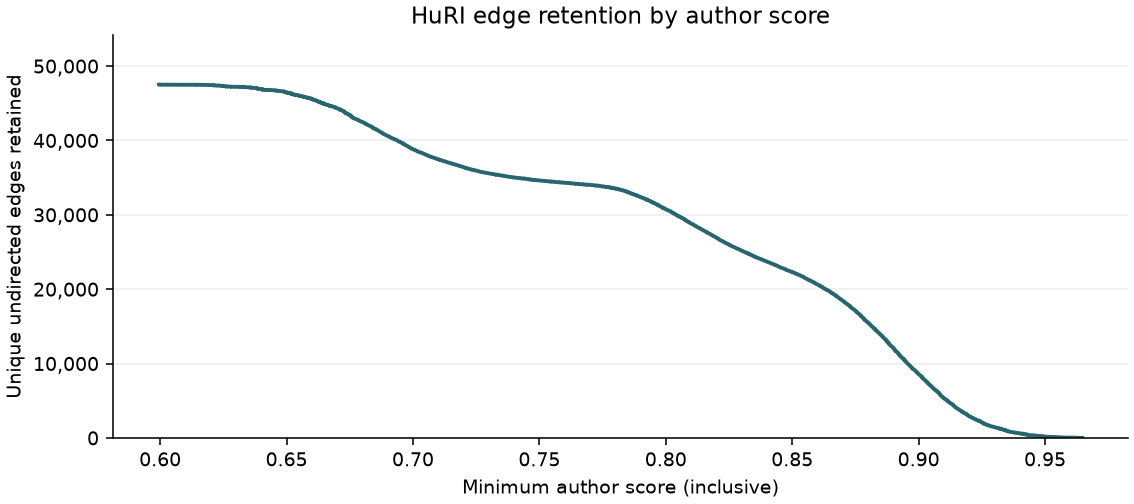

In [5]:
from networks import ISOFORM_SUFFIX

scored_records = pl.scan_csv(
    source, separator="\t", has_header=False, comment_prefix="#",
    quote_char=None, infer_schema=False,
).select(
    pl.nth(0).str.extract(PSI_UNIPROT).str.replace(ISOFORM_SUFFIX, "").alias("a"),
    pl.nth(1).str.extract(PSI_UNIPROT).str.replace(ISOFORM_SUFFIX, "").alias("b"),
    pl.nth(14).str.extract(r"(?:^|\|)author score:\s*([^|]+)")
    .str.strip_chars().cast(pl.Float64, strict=False).alias("score"),
)
scored_edges = (
    scored_records.drop_nulls().filter(pl.col("a") != pl.col("b"), pl.col("score").is_finite())
    .select(pl.min_horizontal("a", "b").alias("a"),
            pl.max_horizontal("a", "b").alias("b"), "score")
    .group_by("a", "b").agg(pl.col("score").max())
    .collect(engine="streaming")
)
retention = (
    scored_edges.group_by("score").len(name="edges")
    .sort("score", descending=True)
    .with_columns(pl.col("edges").cum_sum().alias("retained"))
    .sort("score")
)
total_edges = views["collapse"][0].height
display(Markdown(
    f"**{scored_edges.height:,} of {total_edges:,} unique edges** have a finite author score. "
    f"**{total_edges - scored_edges.height:,}** have no valid score."
))

fig, ax = plt.subplots(figsize=(8.1, 3.6), layout="constrained")
ax.step(retention["score"], retention["retained"], where="pre", color="#27666f", linewidth=2)
ax.set(title="HuRI edge retention by author score", xlabel="Minimum author score (inclusive)",
       ylabel="Unique undirected edges retained", ylim=(0, total_edges * 1.05))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.22)
ax.spines[["top", "right"]].set_visible(False)
with BytesIO() as image:
    fig.savefig(image, format="png", dpi=140)
    display(Image(data=image.getvalue(), width=760))
plt.close(fig)

### Retained edges by policy

The two larger views differ by one edge in the saved run. The audit table separates the reduction from deduplication and the reduction from discarding records with an explicit suffix.

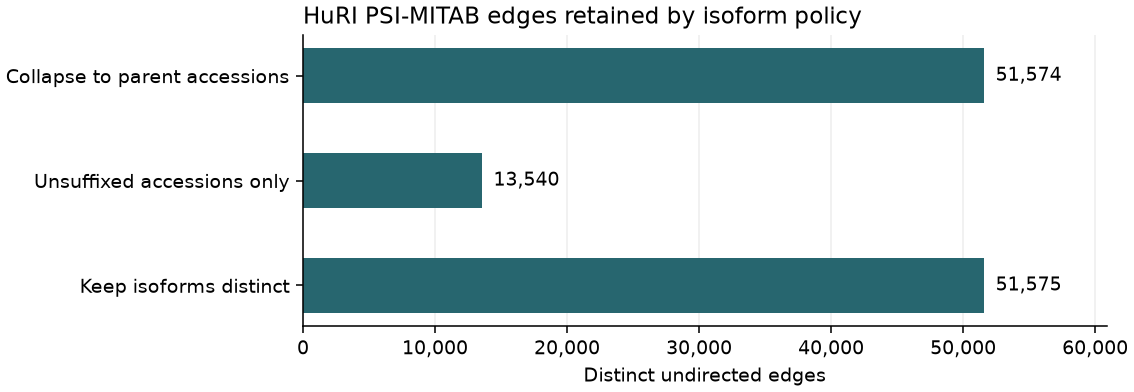

In [6]:
fig, ax = plt.subplots(figsize=(8.1, 2.8), layout="constrained")
bars = ax.barh(audit["Policy"].to_list(), audit["edges"].to_numpy(), color="#27666f", height=0.52)
ax.bar_label(bars, labels=[f"{value:,}" for value in audit["edges"]], padding=6)
ax.invert_yaxis()
ax.set_xlim(0, max(1, audit["edges"].max() * 1.18))
ax.set_xlabel("Distinct undirected edges")
ax.set_title("HuRI PSI-MITAB edges retained by isoform policy", loc="left")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.22)
ax.spines[["top", "right"]].set_visible(False)

with BytesIO() as image:
    fig.savefig(image, format="png", dpi=140)
    display(Image(data=image.getvalue(), width=760), metadata={
        "alt": "Horizontal bars comparing retained edges across the three HuRI isoform policies.",
    })
plt.close(fig)

## Explore an accession

Change **accession** in Setup to inspect its exact ID across the three views. A suffixed query can appear only in the distinct-isoform view. Use the unsuffixed accession to look up its parent in the collapsed view. The preview shows up to six partners per policy.

In [7]:
partner_rows = []
for policy, (edges, _) in views.items():
    partners = edges.filter((pl.col("a") == accession) | (pl.col("b") == accession)).select(
        pl.when(pl.col("a") == accession).then(pl.col("b")).otherwise(pl.col("a")).alias("Partner")
    ).sort("Partner")
    partner_rows.append({
        "Policy": HURI_ISOFORM_POLICIES[policy],
        "Partners for " + accession: partners.height,
        "First partners": ", ".join(partners["Partner"].head(preview_rows)) or "-",
    })
show_table(pl.DataFrame(partner_rows))

| Policy | Partners for Q9HD26-2 | First partners |
| --- | --- | --- |
| Collapse to parent accessions | 0 | - |
| Unsuffixed accessions only | 0 | - |
| Keep isoforms distinct | 16 | E9PSE9, P04004, P08631-2, P55040, Q15746-2, Q68D86-1 |

## Check against the prepared graphs

Each row removal is counted once in the filter sequence. The checks reconcile the input records and confirm that the retained pairs are ordered and unique. Where a validated saved view comes from the same PSI fingerprint, the checks compare every edge and audit count.

In [8]:
dropped = (
    "rows_without_two_uniprot_ids", "source_self_loop_rows",
    "rows_removed_by_isoform_policy", "self_loops_after_isoform_policy", "duplicate_rows",
)
prepared_policies = available_huri_isoform_policies(data_root)
checks = []
for policy, (edges, counts) in views.items():
    assert counts["input_rows"] == counts["edges"] + sum(counts[key] for key in dropped)
    assert edges.filter(pl.col("a") >= pl.col("b")).is_empty()
    assert edges.n_unique() == edges.height

    status = "No validated saved view"
    if policy in prepared_policies:
        path = discover_datasets(data_root, huri_isoforms=policy)["HuRI"]
        saved_audit = json.loads(path.with_suffix(".json").read_text(encoding="utf-8"))
        status = "Saved source fingerprint differs"
        if saved_audit["source"]["sha256"] == source_sha:
            assert edges.equals(pl.read_parquet(path).sort("a", "b"))
            assert all(saved_audit[key] == value for key, value in counts.items())
            status = "Every edge and audit count matches"
    checks.append({"Policy": HURI_ISOFORM_POLICIES[policy], "Saved graph check": status})

show_table(pl.DataFrame(checks))

| Policy | Saved graph check |
| --- | --- |
| Collapse to parent accessions | Every edge and audit count matches |
| Unsuffixed accessions only | Every edge and audit count matches |
| Keep isoforms distinct | Every edge and audit count matches |